Loading data...
Creating features...
Training models...


C:\Users\abhis\AppData\Local\Temp\ipykernel_18944\165569214.py:45: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '11742277.1' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[mask, 'last_airdrop_amount'] = airdrop['amount']
C:\Users\abhis\AppData\Local\Temp\ipykernel_18944\165569214.py:45: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '11742277.1' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[mask, 'last_airdrop_amount'] = airdrop['amount']



Random Forest Results:
Test RMSE: 499,664.53
Train RMSE: 441,797.55
R2 Score: 0.9997

XGBoost Results:
Test RMSE: 590,024.07
Train RMSE: 26,319.16
R2 Score: 0.9996

Best model: Random Forest

Predicting future values...

Predictions saved to 'votable_supply_predictions.csv'
Plot saved as 'votable_supply_prediction_plot.png'

Feature Importance:
                   feature  importance
4          days_from_start    0.486284
7      last_airdrop_amount    0.466841
6  days_since_last_airdrop    0.045191
2                    month    0.001397
1             day_of_month    0.000219
0              day_of_week    0.000034
5       Circulating Supply    0.000025
3                     year    0.000011

Sample of predictions (first 5 rows):
        Date  Predicted_Votable_Supply  Circulating_Supply  VS_CS_Ratio_Percentage
0 2024-12-01              6.276449e+07        1.343236e+09                    4.67
1 2024-12-02              6.281812e+07        1.343236e+09                    4.68
2 2024-12-03 

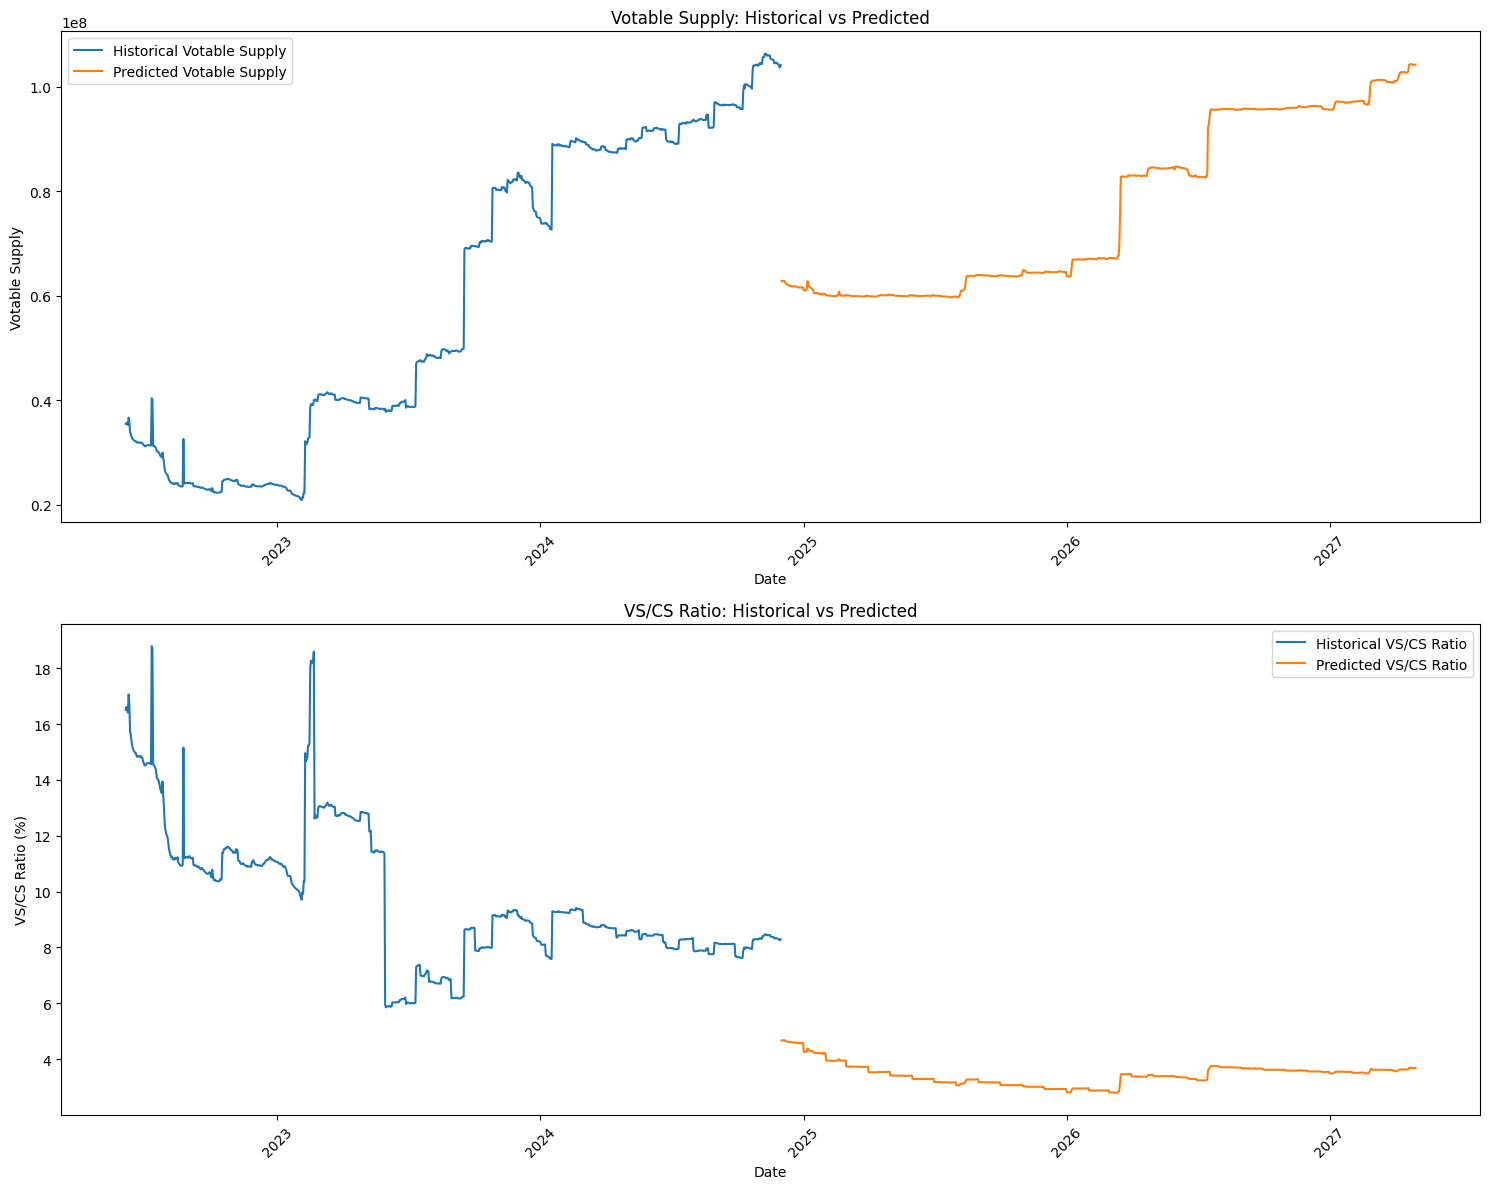

In [33]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from datetime import datetime
import matplotlib.pyplot as plt

def load_historical_data(file_path):
    df = pd.read_csv(file_path)
    df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
    return df

def load_future_data(file_path):
    df = pd.read_csv(file_path)
    df['Date'] = pd.to_datetime(df['Date'])
    return df

def create_features(df):
    df = df.copy()
    df['day_of_week'] = df['Date'].dt.dayofweek
    df['day_of_month'] = df['Date'].dt.day
    df['month'] = df['Date'].dt.month
    df['year'] = df['Date'].dt.year
    df['days_from_start'] = (df['Date'] - df['Date'].min()).dt.days
    
    if 'Votable Supply' in df.columns:
        df['votable_ratio'] = df['Votable Supply'] / df['Circulating Supply']
    
    airdrops = pd.DataFrame([
        {'Date': '2023-02-09', 'amount': 11742277.10},
        {'Date': '2023-09-18', 'amount': 19411313.00}
    ])
    airdrops['Date'] = pd.to_datetime(airdrops['Date'])
    
    df['days_since_last_airdrop'] = 0
    df['last_airdrop_amount'] = 0
    
    for _, airdrop in airdrops.iterrows():
        mask = df['Date'] >= airdrop['Date']
        df.loc[mask, 'days_since_last_airdrop'] = (
            df.loc[mask, 'Date'] - airdrop['Date']).dt.days
        df.loc[mask, 'last_airdrop_amount'] = airdrop['amount']
    
    return df

def train_and_evaluate_models(X_train, X_test, y_train, y_test):
    models = {
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
        'XGBoost': xgb.XGBRegressor(random_state=42)
    }
    
    results = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        mse = mean_squared_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        train_mse = mean_squared_error(y_train, model.predict(X_train))
        
        results[name] = {
            'RMSE': np.sqrt(mse),
            'R2': r2,
            'Train_RMSE': np.sqrt(train_mse),
            'model': model
        }
    
    return results

def create_visualizations(historical_df, predictions_df):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12))
    
    # Plot 1: Votable Supply
    ax1.plot(historical_df['Date'], historical_df['Votable Supply'], 
            label='Historical Votable Supply')
    ax1.plot(predictions_df['Date'], predictions_df['Predicted_Votable_Supply'], 
            label='Predicted Votable Supply')
    ax1.set_title('Votable Supply: Historical vs Predicted')
    ax1.set_xlabel('Date')
    ax1.set_ylabel('Votable Supply')
    ax1.legend()
    ax1.tick_params(axis='x', rotation=45)
    
    # Plot 2: VS/CS Ratio
    historical_ratio = (historical_df['Votable Supply'] / historical_df['Circulating Supply'] * 100)
    ax2.plot(historical_df['Date'], historical_ratio, 
            label='Historical VS/CS Ratio')
    ax2.plot(predictions_df['Date'], predictions_df['VS_CS_Ratio_Percentage'], 
            label='Predicted VS/CS Ratio')
    ax2.set_title('VS/CS Ratio: Historical vs Predicted')
    ax2.set_xlabel('Date')
    ax2.set_ylabel('VS/CS Ratio (%)')
    ax2.legend()
    ax2.tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.savefig('votable_supply_prediction_plot.png')

def predict_votable_supply():
    try:
        # Load data
        print("Loading data...")
        historical_df = load_historical_data('../../../data/votable_supply-dhruvi/data/pr_raw_data.csv')
        future_df = load_future_data('../../../data/votable_supply_framework/future_vs_prediction/future_cs_data.csv')
        
        # Create features
        print("Creating features...")
        historical_df_featured = create_features(historical_df)
        future_df_featured = create_features(future_df)
        
        # Prepare features for modeling
        feature_columns = [
            'day_of_week', 'day_of_month', 'month', 'year',
            'days_from_start', 'Circulating Supply',
            'days_since_last_airdrop', 'last_airdrop_amount'
        ]
        
        X = historical_df_featured[feature_columns]
        y = historical_df_featured['Votable Supply']
        
        # Split data
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )
        
        # Scale features
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)
        
        # Train and evaluate models
        print("Training models...")
        results = train_and_evaluate_models(X_train_scaled, X_test_scaled, y_train, y_test)
        
        # Print results
        for name, metrics in results.items():
            print(f"\n{name} Results:")
            print(f"Test RMSE: {metrics['RMSE']:,.2f}")
            print(f"Train RMSE: {metrics['Train_RMSE']:,.2f}")
            print(f"R2 Score: {metrics['R2']:.4f}")
        
        # Select best model
        best_model_name = min(results.items(), key=lambda x: x[1]['RMSE'])[0]
        best_model = results[best_model_name]['model']
        print(f"\nBest model: {best_model_name}")
        
        # Predict future values
        print("\nPredicting future values...")
        future_features = future_df_featured[feature_columns]
        future_features_scaled = scaler.transform(future_features)
        future_predictions = best_model.predict(future_features_scaled)
        
        # Create results DataFrame
        predictions_df = pd.DataFrame({
            'Date': future_df_featured['Date'],
            'Predicted_Votable_Supply': future_predictions,
            'Circulating_Supply': future_df_featured['Circulating Supply'],
            'VS_CS_Ratio_Percentage': (future_predictions / future_df_featured['Circulating Supply'] * 100).round(2)
        })
        
        # Save predictions
        predictions_df.to_csv('votable_supply_predictions.csv', index=False)
        print("\nPredictions saved to 'votable_supply_predictions.csv'")
        
        # Create visualizations
        create_visualizations(historical_df, predictions_df)
        print("Plot saved as 'votable_supply_prediction_plot.png'")
        
        # Print feature importance for Random Forest
        if 'Random Forest' in results:
            rf_model = results['Random Forest']['model']
            feature_importance = pd.DataFrame({
                'feature': feature_columns,
                'importance': rf_model.feature_importances_
            })
            print("\nFeature Importance:")
            print(feature_importance.sort_values('importance', ascending=False))
        
        # Print sample of predictions
        print("\nSample of predictions (first 5 rows):")
        print(predictions_df.head().to_string())
            
    except Exception as e:
        print(f"An error occurred: {str(e)}")
        raise

if __name__ == "__main__":
    predict_votable_supply()